# Fitbit 心率生理整合

強度分區、心率恢復（HRR）、每日負荷——動作×負荷的整合敘事。

> **資料來源**：主要路徑是 Kaggle FitBit 資料集（`data/raw/fitbit/`，
> kagglehub 已需登入，改手動下載解壓即可——見 README）。本 notebook 在
> Fitbit 資料缺席時**自動改用 PAMAP2 的同步心率**做同一套分析（9 受試者、
> 秒級 HR＋活動標籤），讓示範不依賴外部下載。


In [1]:

import sys; sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# dataviz 慣例（與 reports/figures 同一視覺系統）
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlesize": 10.5,
})

from pathlib import Path

from src.isa.config import FITBIT_DIR, RAW_DIR, DEFAULT_MAX_HR
from src.isa.physio.hr_analysis import (hr_zone_percentages, hr_recovery,
                                        daily_load_summary)

try:
    hr = __import__("src.isa.physio.hr_analysis", fromlist=["load_fitbit_heartrate"]) \
        .load_fitbit_heartrate(FITBIT_DIR)
    SOURCE = "fitbit"
    print(f"Fitbit data loaded: {len(hr)} rows, {hr['Id'].nunique()} users")
except FileNotFoundError:
    print("Fitbit 資料未下載——改用 PAMAP2 同步心率示範（Protocol 場次）")
    SOURCE = "pamap2"
    from src.isa.data.loader_pamap2 import load_subject
    # 明確指定 Protocol 場次：**/glob 會同時比對 Optional/（談判活動場次），
    # 那裡沒有運動段落，不能當 HRR 示範
    proto = RAW_DIR / "PAMAP2_Dataset" / "Protocol"
    sec = load_subject(proto / "subject101.dat")
    sec["t"] = sec["t"] - sec["t"].iloc[0]      # 相對秒（錄製起點為 0）
    print(f"PAMAP2 subject101 (Protocol): {len(sec)} seconds, "
          f"{sec['activity'].nunique()} activities")


Fitbit 資料未下載——改用 PAMAP2 同步心率示範（Protocol 場次）


PAMAP2 subject101 (Protocol): 2510 seconds, 12 activities


## 1. 強度分區：%HRmax 的時間占比

以 190 bpm 估 HRmax（受試者 24-32 歲的年齡公式近似）。分區用
`src/isa/physio/hr_analysis.hr_zone_percentages`——與管線同一份定義。


mean %HRmax = 64.3


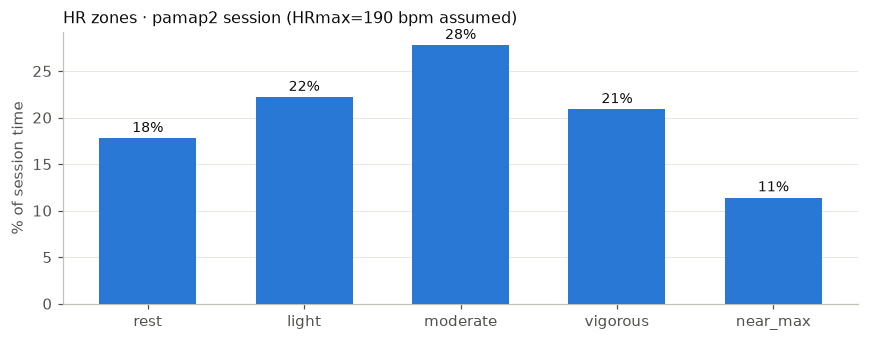

In [2]:
s = sec["hr"].reset_index(drop=True)
zones = hr_zone_percentages(s)
zs = pd.Series({k: v for k, v in zones.items() if not k.startswith("_")})
print(f"mean %HRmax = {zones['_mean_pct_hrmax']:.1f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.bar(zs.index, zs.values, width=0.62, color=BLUE, zorder=3)
ax.bar_label(bars, fmt="%.0f%%", fontsize=9, color=INK, padding=2)
ax.set_ylabel("% of session time")
ax.grid(axis="y", lw=0.5, color=GRID); ax.set_axisbelow(True)
ax.set_title(f"HR zones · {SOURCE} session (HRmax={DEFAULT_MAX_HR} bpm assumed)",
             loc="left", color=INK)
fig.tight_layout()
plt.show()


## 2. 心率恢復（HRR）：高強度段落結束後的 1 分鐘

HRR＝峰值心率 − 結束後 1 分鐘內最低心率；**< 12 bpm 是疲勞/心血管風險的
經典門檻**。錨點取自最強運動區塊的結束點——且該點之後 60 秒內至少 30 秒
有 HR 資料（PAMAP2 的 HR 在活動轉換處常有缺值 gap，恢復窗不存在時 HRR
無法定義，必須跳過）。


anchor: ascending_stairs 結束於 t=1894s (peak 169 bpm)
HRR(1min) = 34.0 bpm ——高於 12 bpm 門檻，恢復正常


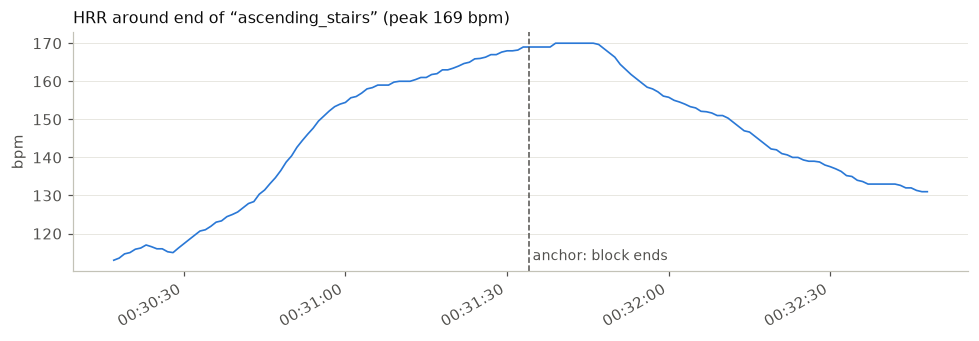

In [3]:
# 錨點＝最強運動區塊的結束秒；條件：區塊 >60s、屬 12 個分析內活動
# （談判活動 9/10/11 如開車，心率再高也不是運動負荷）、且恢復窗存在
sec["block"] = (sec["activity"].diff() != 0).cumsum()
blocks = (sec.groupby(["block", "activity"])
             .agg(start=("t", "first"), end=("t", "last"),
                  peak_hr=("hr", "max"), n=("t", "size"))
             .reset_index())
NAME = {1: "lying", 2: "sitting", 3: "standing", 4: "walking", 5: "running",
        6: "cycling", 7: "nordic_walking", 12: "ascending_stairs",
        13: "descending_stairs", 16: "vacuum_cleaning", 17: "ironing",
        24: "rope_jumping"}
blocks["name"] = blocks["activity"].map(NAME)
cand = blocks[(blocks["n"] > 60) & blocks["activity"].isin(NAME)]
has_recovery = [((sec["t"] > e) & (sec["t"] <= e + 60)).sum() >= 30
                for e in cand["end"]]
cand = cand[has_recovery]
best = cand.sort_values("peak_hr").iloc[-1]
anchor_t = float(best["end"])
print(f"anchor: {best['name']} 結束於 t={anchor_t:.0f}s (peak {best['peak_hr']:.0f} bpm)")

# hr_recovery 以 Timestamp 為介面——本 session 給虛擬日期，秒→ns
t0 = pd.Timestamp("2026-01-01")
times = t0 + pd.to_timedelta(sec["t"], unit="s")
anchor = t0 + pd.Timedelta(seconds=anchor_t)
hrr = hr_recovery(sec["hr"].reset_index(drop=True), times, anchor)
print(f"HRR(1min) = {hrr} bpm", "——高於 12 bpm 門檻，恢復正常"
      if hrr and hrr >= 12 else "——低於 12 bpm：疲勞/風險訊號" if hrr else "")

win = ((times >= anchor - pd.Timedelta(seconds=90))
       & (times <= anchor + pd.Timedelta(seconds=150))).to_numpy()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(times[win], sec["hr"].reset_index(drop=True)[win], lw=1.1, color=BLUE)
ax.axvline(anchor, color=INK2, lw=1, ls="--")
ax.text(anchor, ax.get_ylim()[0] + 2, " anchor: block ends", fontsize=9,
        color=INK2, va="bottom")
ax.set_ylabel("bpm")
ax.set_title(f"HRR around end of “{best['name']}” (peak {best['peak_hr']:.0f} bpm)",
             loc="left", color=INK)
ax.grid(axis="y", lw=0.5, color=GRID); ax.set_axisbelow(True)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


## 3. 每日負荷：分鐘級心率 × 強度加權（簡化 TRIMP）

分鐘級聚合後丟給 `daily_load_summary`——「這天身體總共付出多少」的
單一數字（加權分鐘數），以及中強度以上分鐘數、峰值/安靜心率代理。


In [4]:
minute = sec.groupby(np.floor(sec["t"] / 60))["hr"].mean()
summary = daily_load_summary(minute)
pd.Series(summary).rename(f"{SOURCE} session load").to_frame()


,pamap2 session load
weighted_load_minutes,134.0
moderate_plus_minutes,34.0
peak_hr,181.0
resting_hr_proxy,87.0


## 接上實機 Fitbit 的兩個待辦

1. 手動下載 Kaggle FitBit 資料集解壓到 `data/raw/fitbit/`（含
   `heartrate_seconds_merged.csv`）→ 本 notebook 第一格自動改走 Fitbit 路徑
2. `daily_load_summary` 以「天」為單位分組（Fitbit 有真實日期；PAMAP2 的
   session 只是單日示範）

**v2 延伸**：RR-interval（HRV）疲勞監測需原始 ECG/PPG——智慧手錶接上後
以 `hr_analysis` 同層擴充（findings 限制 #3）。
